In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 32.81it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:07<00:00, 47.54it/s]


In [ ]:
# from utils import unflatten_maps


# nifti_obj = unflatten_maps(
#     TD_maps=maps_ucsf, 
#     template=T1_file, 
#     return_nifti=True
# )

# nib.save(nifti_obj, 'loading_maps_result.nii.gz')

# from nilearn import image


# nifti_img_4d = unflatten_maps(maps_ucsf, T1_file, return_nifti=True)

# nifti_img_3d = image.index_img(nifti_img_4d, 0)

# plotting.plot_glass_brain(nifti_img_3d, colorbar=True, display_mode='lyrz', black_bg=True, title='Statistical Map')

# from nilearn import plotting


# nifti_img_3d = image.index_img(nifti_img_4d, 100)


# plotting.plot_stat_map(
#     nifti_img_3d, 
#     bg_img=T1_file, 
#     display_mode='z',
#     cut_coords=7,
#     threshold=0.3,
#     title="Axial Loading Map Series",
#     colorbar=True,
#     cmap='viridis'
# )

In [5]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:10<00:00, 46.28it/s]


# KernelPCA

INFO:	TD maps were masked.
Training Concordance Index: 0.6738
Testing Concordance Index: 0.5920


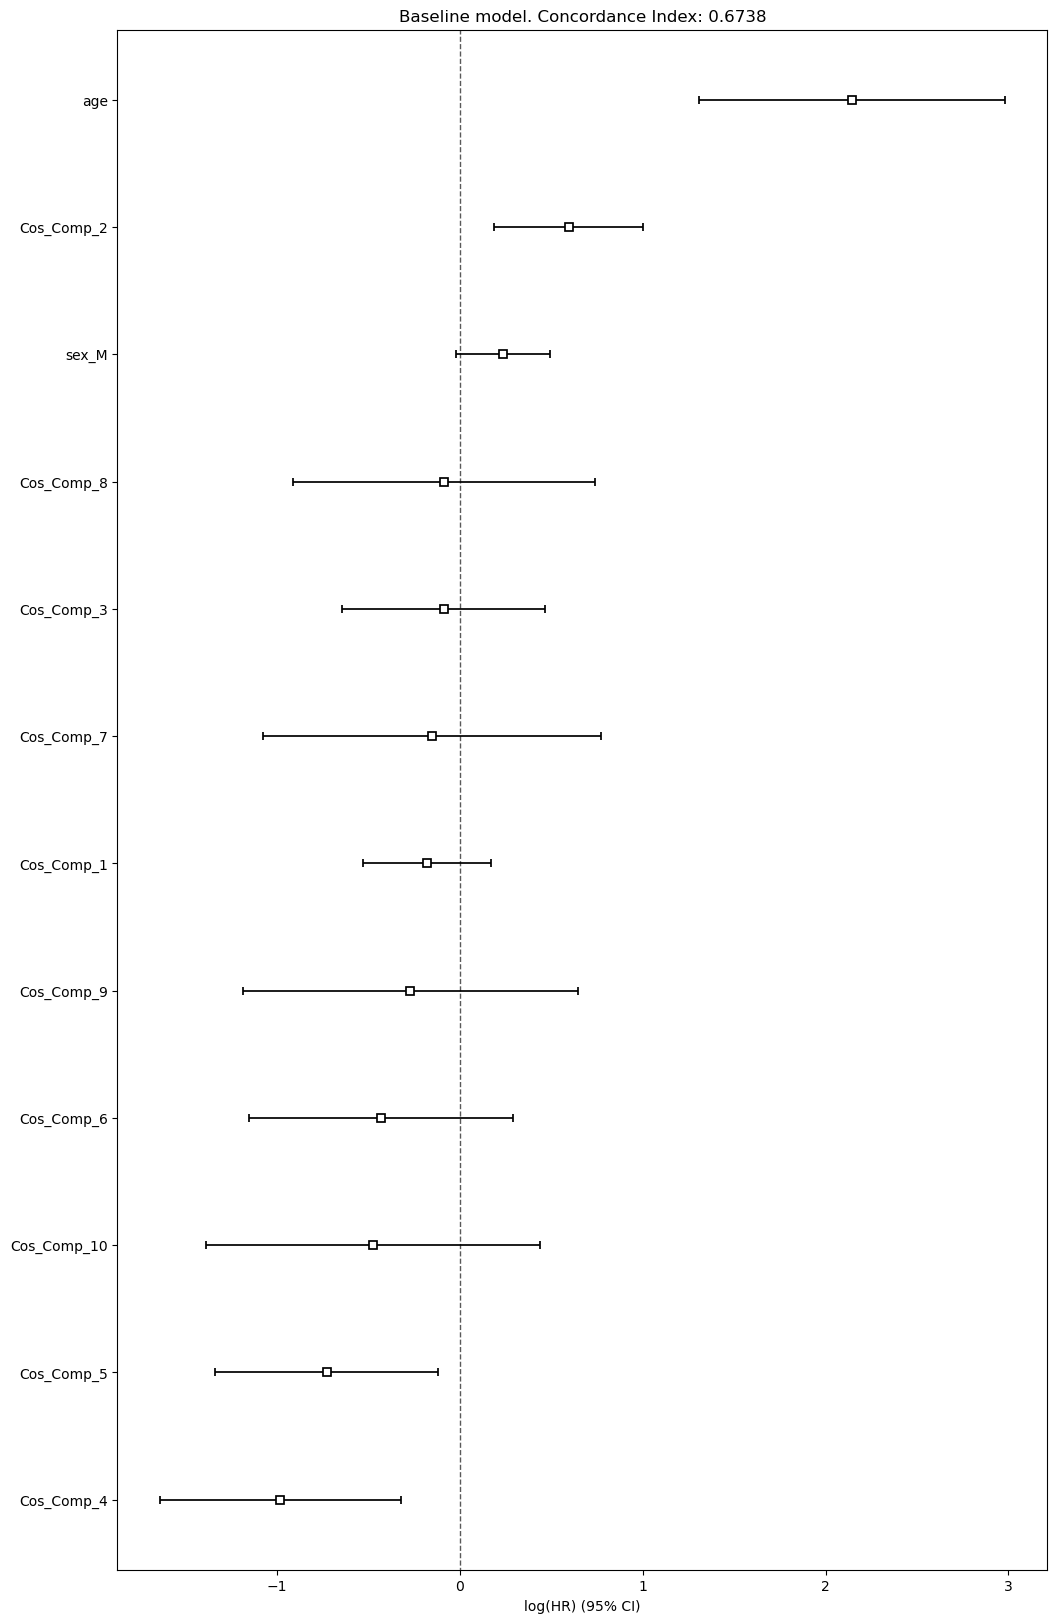

In [ ]:
from dataclasses import dataclass, field

from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA
import sklearn

from typing import TypeAlias, Union


normalization = None#'min_max'
# save_dir = "results/"
n_components = 10

sklearn.set_config(transform_output="default")

from enum import Enum
from typing import NamedTuple
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


@dataclass
class Dataset:
    name: str
    path: str
    maps: np.ndarray
    df: pd.DataFrame


Projector: TypeAlias = Union[TD_Kernel_PCA, TD_PCA]

class Trainer:
    def __init__(self, projector: Projector):
        self.projector = projector

    def fit_transform(self, norm):
        return self.projector.fit_pca_maps(norm=norm)
    
    def transform(self, maps):
        return self.projector.transform_maps(maps)


site_idx_training = 1
site_idx_testing = 0

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

td_kpca = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)

trainer = Trainer(td_kpca)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_training_new_features = pd.DataFrame(
    comps_training, 
    columns=[f"Cos_Comp_{i+1}" for i in range(n_components)], 
    index=df_training.index
)

df_training_all = pd.concat([df_training, df_training_new_features], axis=1)

columns_to_drop = ["volume", "site", "OS", "ID", "ltdi", "tdi"]
df_training_all = df_training_all.drop(columns=columns_to_drop)

categorical_features = df_training_all.select_dtypes(include="object").columns
numerical_features = df_training_all.select_dtypes(exclude="object").columns
numerical_columns_to_drop = ["OS (corrected)", "status"]
numerical_features = numerical_features.drop(numerical_columns_to_drop)

enc_pipe = EncodingPipeline(df_training_all)
X_train = enc_pipe.fit_transform(list(numerical_features), list(categorical_features))


penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

cph = CoxPHFitter(penalizer=penalizer)
cph.fit(X_train, duration_col, event_col=event_col)

print(f"Training Concordance Index: {cph.concordance_index_:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"Baseline model. Concordance Index: {cph.concordance_index_:.4f}")
cph.plot(ax = ax)


df_testing_new_features = pd.DataFrame(
    comps_testing, 
    columns=[f"Cos_Comp_{i+1}" for i in range(n_components)], 
    index=df_testing.index
)

df_testing_all = pd.concat([df_testing, df_testing_new_features], axis=1)

df_testing_all = df_testing_all.drop(columns=columns_to_drop)

X_test = enc_pipe.transform(df_testing_all)
c_index_test = cph.score(X_test, "concordance_index")

print(f"Testing Concordance Index: {c_index_test:.4f}")